In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Start from the notebook's current directory
CURRENT_DIR = Path.cwd()
DATASET_NAME = "Mahanadi_Riverbank_Erosion_2018_2024_ML_Ready.csv"

# Search the current directory and its parent folders
DATA_PATH = None

for folder in [CURRENT_DIR, *CURRENT_DIR.parents]:
    candidate = folder / DATASET_NAME
    if candidate.exists():
        DATA_PATH = candidate
        break

if DATA_PATH:
    df = pd.read_csv(DATA_PATH)

    print("Dataset found:", DATA_PATH)
    print("Dataset shape:", df.shape)
    print("\nColumn names:")
    print(df.columns.tolist())

    display(df.head())
else:
    print("Dataset not found in the current or parent folders.")
    print("Notebook directory:", CURRENT_DIR)

Dataset found: c:\Users\salon\Mahanadi_Riverbank_Erosion_2018_2024_ML_Ready.csv
Dataset shape: (6000, 11)

Column names:
['NDVI', 'NDWI', 'Elevation', 'Rainfall', 'LandCover', 'Distance_From_River', 'Label', 'Feature_Year', 'Prediction_Year', 'Latitude', 'Longitude']


,NDVI,NDWI,Elevation,Rainfall,LandCover,Distance_From_River,Label,Feature_Year,Prediction_Year,Latitude,Longitude
0,-0.193380,0.431204,188,1817.867509,0,0.000000,0,2018,2019,21.582788,83.877540
1,0.460902,-0.478127,177,1837.575458,4,1060.660172,0,2018,2019,21.542454,84.092327
2,0.477690,-0.500833,167,1883.515178,4,875.956620,0,2018,2019,21.465289,84.039236
3,-0.256851,0.460774,188,1879.656287,0,0.000000,0,2018,2019,21.569314,83.973120
4,0.692994,-0.642158,182,1864.480601,1,934.344690,0,2018,2019,21.471218,83.985158


In [3]:
# Inspect the environmental variables and target label

environmental_features = [
    "NDVI",
    "NDWI",
    "Elevation",
    "Rainfall",
    "LandCover",
    "Distance_From_River"
]

print("Environmental feature summary:")
display(df[environmental_features].describe().T)

print("\nLabel distribution:")
display(df["Label"].value_counts().sort_index().rename(
    index={0: "Stable / not identified by proxy",
           1: "Potential erosion"}
).to_frame("Number of samples"))

print("\nSamples by feature year:")
display(
    df.groupby(["Feature_Year", "Prediction_Year"])
      .size()
      .rename("Number of samples")
      .reset_index()
)

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing values"))

Environmental feature summary:


,count,mean,std,min,25%,50%,75%,max
NDVI,6000.0,0.287480,0.252036,-0.403923,0.079607,0.330318,0.491376,0.790647
NDWI,6000.0,-0.244276,0.298913,-0.683592,-0.489451,-0.370212,0.020540,0.580381
Elevation,6000.0,175.126000,30.885759,123.000000,156.000000,172.000000,190.000000,513.000000
Rainfall,6000.0,1692.765117,164.487955,1425.125936,1540.388427,1660.807395,1830.135015,2031.338850
LandCover,6000.0,1.566167,2.014439,0.000000,0.000000,1.000000,4.000000,7.000000
Distance_From_River,6000.0,339.213212,446.070409,0.000000,14.142136,30.000000,627.773829,1280.000000



Label distribution:


,Number of samples
Label,
Stable / not identified by proxy,3000
Potential erosion,3000



Samples by feature year:


,Feature_Year,Prediction_Year,Number of samples
0,2018,2019,1000
1,2019,2020,1000
2,2020,2021,1000
3,2021,2022,1000
4,2022,2023,1000
5,2023,2024,1000



Missing values:


,Missing values
NDVI,0
NDWI,0
Elevation,0
Rainfall,0
LandCover,0
Distance_From_River,0
Label,0
Feature_Year,0
Prediction_Year,0
Latitude,0


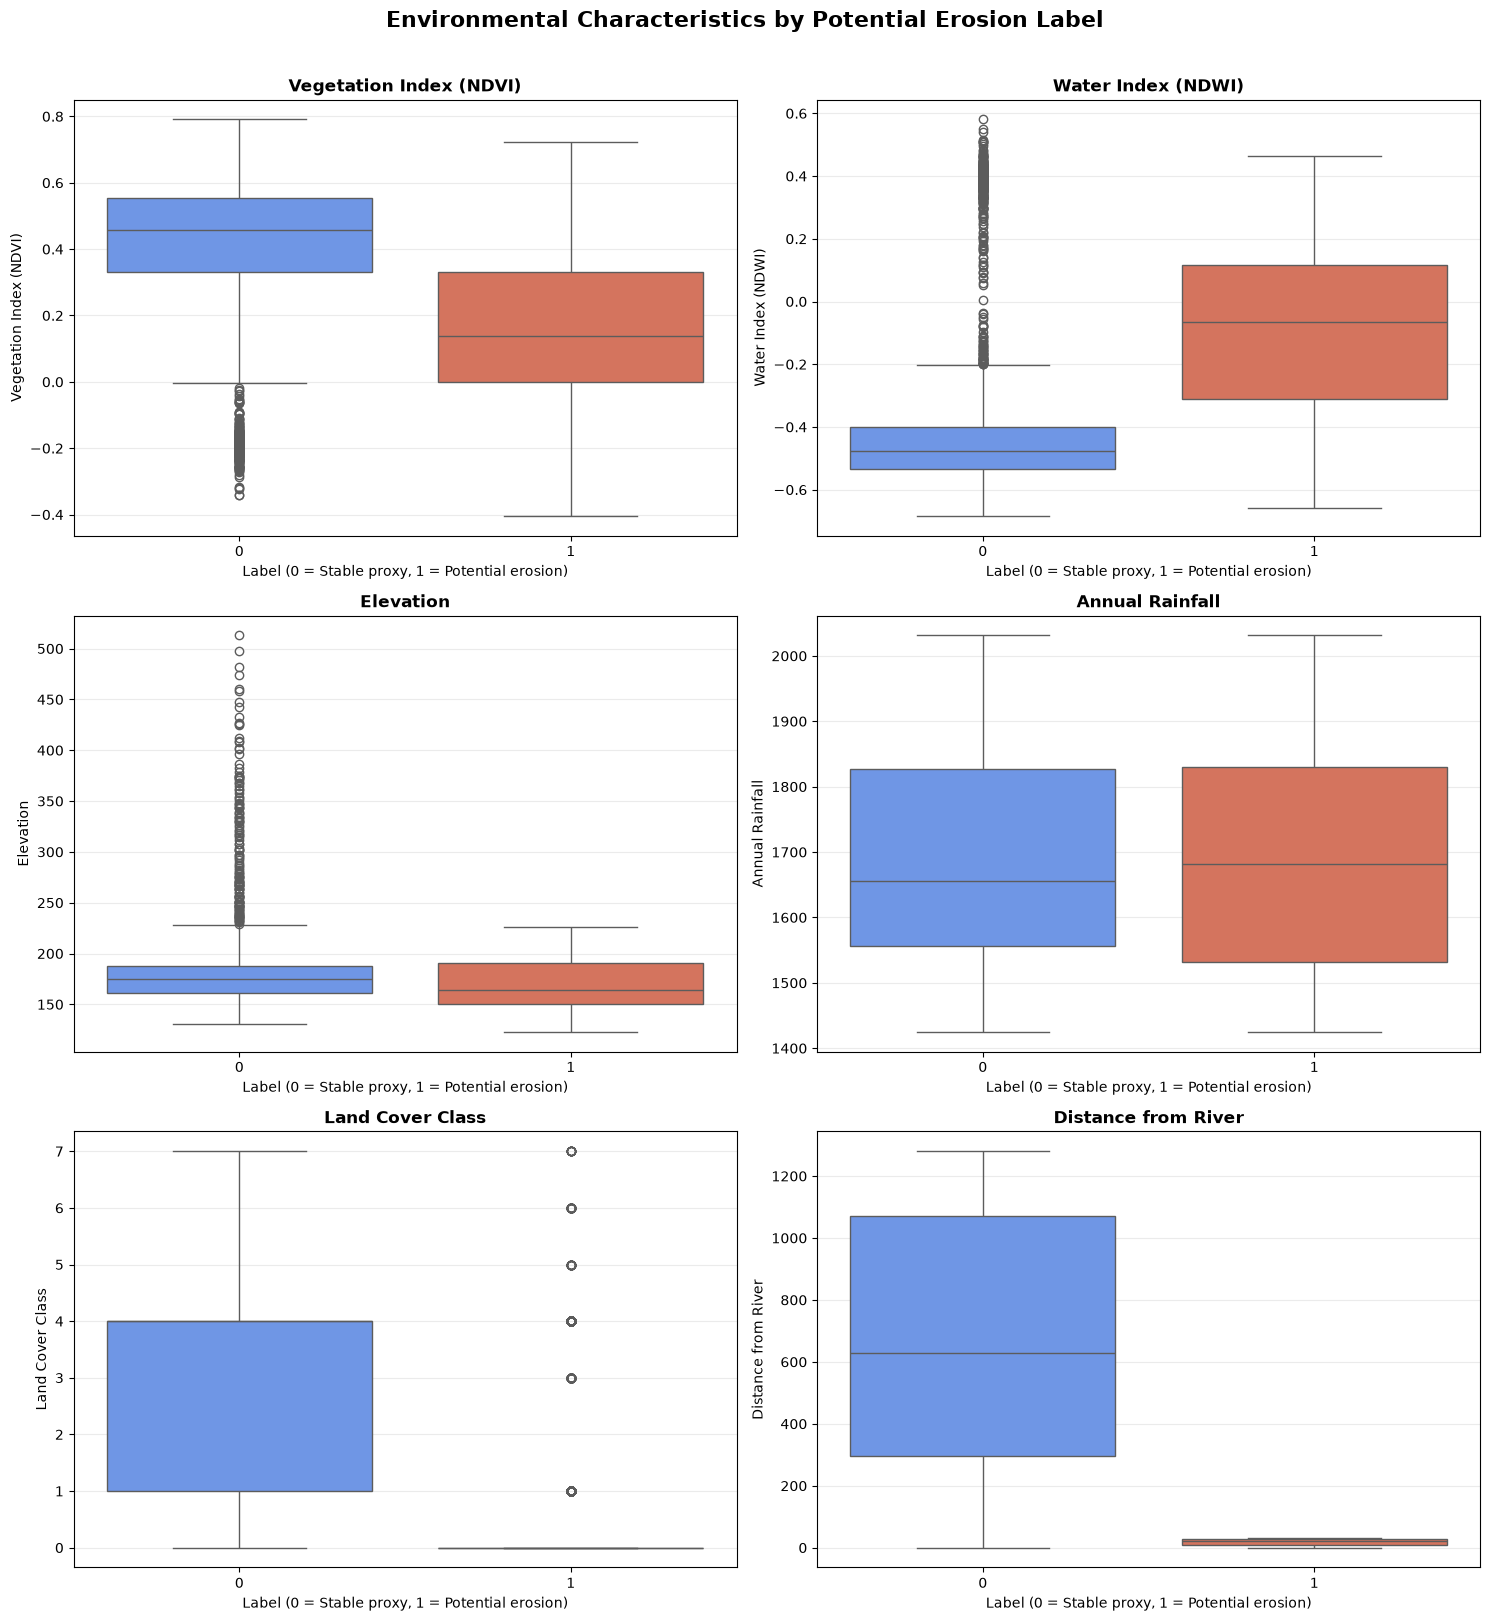

In [4]:

import matplotlib.pyplot as plt
import seaborn as sns

# Friendly labels for the charts
feature_names = {
    "NDVI": "Vegetation Index (NDVI)",
    "NDWI": "Water Index (NDWI)",
    "Elevation": "Elevation",
    "Rainfall": "Annual Rainfall",
    "LandCover": "Land Cover Class",
    "Distance_From_River": "Distance from River"
}

# Create a 2-column grid of boxplots
fig, axes = plt.subplots(3, 2, figsize=(15, 16))
axes = axes.flatten()

for ax, feature in zip(axes, feature_names):
    sns.boxplot(
        data=df,
        x="Label",
        y=feature,
        hue="Label",
        order=[0, 1],
        hue_order=[0, 1],
        palette=["#5B8FF9", "#E8684A"],
        legend=False,
        ax=ax
    )

    ax.set_title(feature_names[feature], fontsize=12, fontweight="bold")
    ax.set_xlabel("Label (0 = Stable proxy, 1 = Potential erosion)")
    ax.set_ylabel(feature_names[feature])
    ax.grid(axis="y", alpha=0.25)

plt.suptitle(
    "Environmental Characteristics by Potential Erosion Label",
    fontsize=16,
    fontweight="bold",
    y=1.01
)
plt.tight_layout()
plt.show()


In [5]:

# Compare the median of each environmental variable by label
median_comparison = df.groupby("Label")[
    environmental_features
].median().T

median_comparison.columns = [
    "Stable / not identified by proxy (0)",
    "Potential erosion (1)"
]

median_comparison["Difference (1 - 0)"] = (
    median_comparison["Potential erosion (1)"]
    - median_comparison["Stable / not identified by proxy (0)"]
)

display(median_comparison.round(4))


,Stable / not identified by proxy (0),Potential erosion (1),Difference (1 - 0)
NDVI,0.4562,0.1369,-0.3193
NDWI,-0.4769,-0.0639,0.4130
Elevation,175.0000,164.0000,-11.0000
Rainfall,1656.2455,1681.4159,25.1705
LandCover,4.0000,0.0000,-4.0000
Distance_From_River,627.8535,20.0000,-607.8535


,Stable / not identified by proxy (0),Potential erosion (1)
LandCover,,
0,11.50,85.87
1,37.37,4.80
3,0.63,2.27
4,32.20,4.70
5,8.90,0.80
6,9.27,1.23
7,0.13,0.33


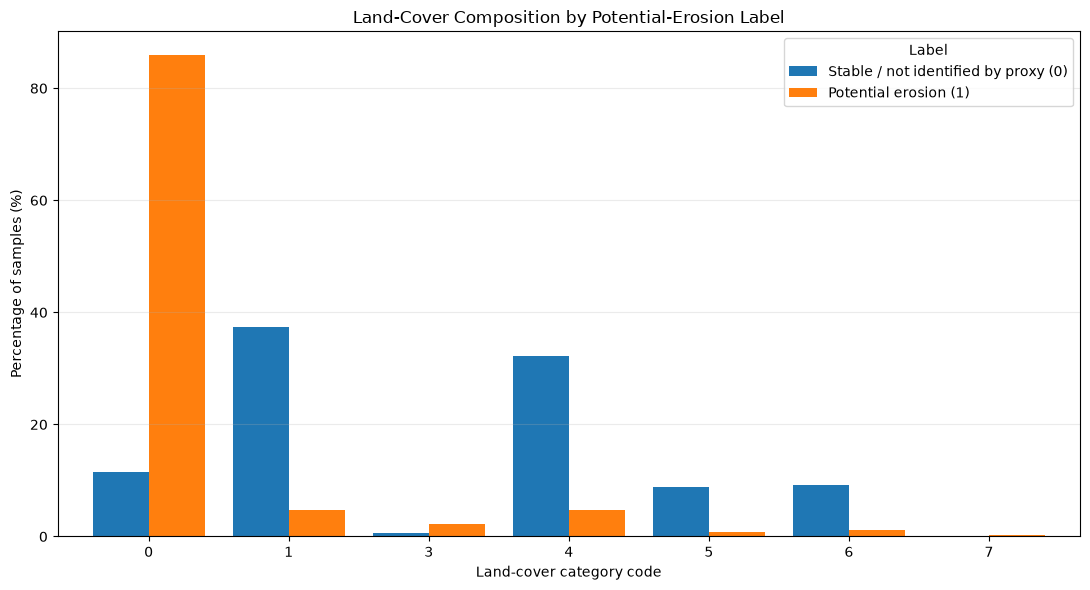

In [6]:

# Distribution of land-cover categories in each label class

landcover_counts = pd.crosstab(
    df["LandCover"],
    df["Label"],
    normalize="columns"
) * 100

landcover_counts.columns = [
    "Stable / not identified by proxy (0)",
    "Potential erosion (1)"
]

display(landcover_counts.round(2))

ax = landcover_counts.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

ax.set_title("Land-Cover Composition by Potential-Erosion Label")
ax.set_xlabel("Land-cover category code")
ax.set_ylabel("Percentage of samples (%)")
ax.legend(title="Label")
ax.grid(axis="y", alpha=0.25)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [7]:

# Exact land-cover percentages by label

landcover_summary = pd.crosstab(
    df["LandCover"],
    df["Label"],
    normalize="columns"
).mul(100)

landcover_summary.columns = [
    "Stable proxy (%)",
    "Potential erosion (%)"
]

landcover_summary["Difference (percentage points)"] = (
    landcover_summary["Potential erosion (%)"]
    - landcover_summary["Stable proxy (%)"]
)

display(landcover_summary.round(2))


,Stable proxy (%),Potential erosion (%),Difference (percentage points)
LandCover,,,
0,11.50,85.87,74.37
1,37.37,4.80,-32.57
3,0.63,2.27,1.63
4,32.20,4.70,-27.50
5,8.90,0.80,-8.10
6,9.27,1.23,-8.03
7,0.13,0.33,0.20


## Environmental Interpretation of Potential Riverbank Erosion

The environmental characteristics of the two classes were compared using vegetation, water, elevation, rainfall, land-cover and river-distance variables.

**Vegetation (NDVI):** The median NDVI was 0.1369 for potential-erosion samples and 0.4562 for stable-proxy samples. This indicates lower vegetation-index values in the potential-erosion class, suggesting differences in vegetation cover or exposed surface conditions.

**Water conditions (NDWI):** The median NDWI was −0.0639 for potential-erosion samples, compared with −0.4769 for stable-proxy samples. The higher values indicate a stronger water-related spectral signal in the potential-erosion class.

**Elevation:** The median elevation was 164 for potential-erosion samples and 175 for stable-proxy samples. This suggests that potential-erosion samples tend to occur at lower elevations in this dataset.

**Rainfall:** Median rainfall was approximately 1,681.42 for potential-erosion samples and 1,656.25 for stable-proxy samples. The relatively modest difference and substantial overlap between the distributions suggest that rainfall alone does not clearly distinguish the two classes in the exploratory comparison.

**Land cover:** Category 0 represented 85.87% of potential-erosion samples and 11.50% of stable-proxy samples. Category 1 and category 4 were more prevalent in the stable-proxy class. This strong difference requires careful interpretation because the labels were derived from satellite-observed water contraction, which may create a relationship between water-related predictors and the target.

**Distance from the river:** The median distance was 20 for potential-erosion samples and approximately 627.85 for stable-proxy samples. The potential-erosion samples were therefore much closer to the mapped river boundary, consistent with the spatial nature of the target.

### Overall interpretation

The exploratory analysis identifies vegetation index, water index, elevation, land cover and river proximity as variables associated with the satellite-derived potential-erosion labels. These patterns help explain the model's classifications, but they do not establish causation or independently verified riverbank erosion. Because the target is a water-contraction proxy, the findings should be interpreted as environmental associations with potential erosion rather than confirmed erosion events.

In [8]:

from pathlib import Path

# Search common project locations for existing SHAP outputs
search_roots = [
    Path.cwd(),
    *Path.cwd().parents,
    Path.home()
]

extensions = {".csv", ".png", ".jpg", ".jpeg", ".pdf"}

for root in search_roots:
    if not root.exists():
        continue

    matches = [
        p for p in root.rglob("*")
        if p.is_file()
        and p.suffix.lower() in extensions
        and "shap" in p.name.lower()
    ]

    if matches:
        print(f"\nSHAP files found under: {root}")
        for path in matches[:30]:
            print(path)
        break
else:
    print("No files with 'shap' in the filename were found.")



SHAP files found under: c:\Users\salon\OneDrive\ドキュメント\ml_miniproject
c:\Users\salon\OneDrive\ドキュメント\ml_miniproject\results\random_forest_shap_feature_importance.csv
c:\Users\salon\OneDrive\ドキュメント\ml_miniproject\results\random_forest_shap_feature_importance.png
c:\Users\salon\OneDrive\ドキュメント\ml_miniproject\results\random_forest_shap_summary.png
c:\Users\salon\OneDrive\ドキュメント\ml_miniproject\results\shap_dependence_distance_from_river.png
c:\Users\salon\OneDrive\ドキュメント\ml_miniproject\results\shap_dependence_ndvi.png
c:\Users\salon\OneDrive\ドキュメント\ml_miniproject\results\shap_dependence_ndwi.png


SHAP importance file: c:\Users\salon\OneDrive\ドキュメント\ml_miniproject\results\random_forest_shap_feature_importance.csv

Columns: ['Feature', 'Mean_Absolute_SHAP']

Feature importance values:


,Feature,Mean_Absolute_SHAP
0,numeric__Distance_From_River,0.317947
1,numeric__NDWI,0.074651
2,categorical__LandCover_0,0.062558
3,numeric__NDVI,0.028790
4,numeric__Elevation,0.013919
5,numeric__Rainfall,0.010585
6,categorical__LandCover_1,0.009688
7,categorical__LandCover_4,0.006430
8,categorical__LandCover_6,0.002608
9,categorical__LandCover_5,0.001558


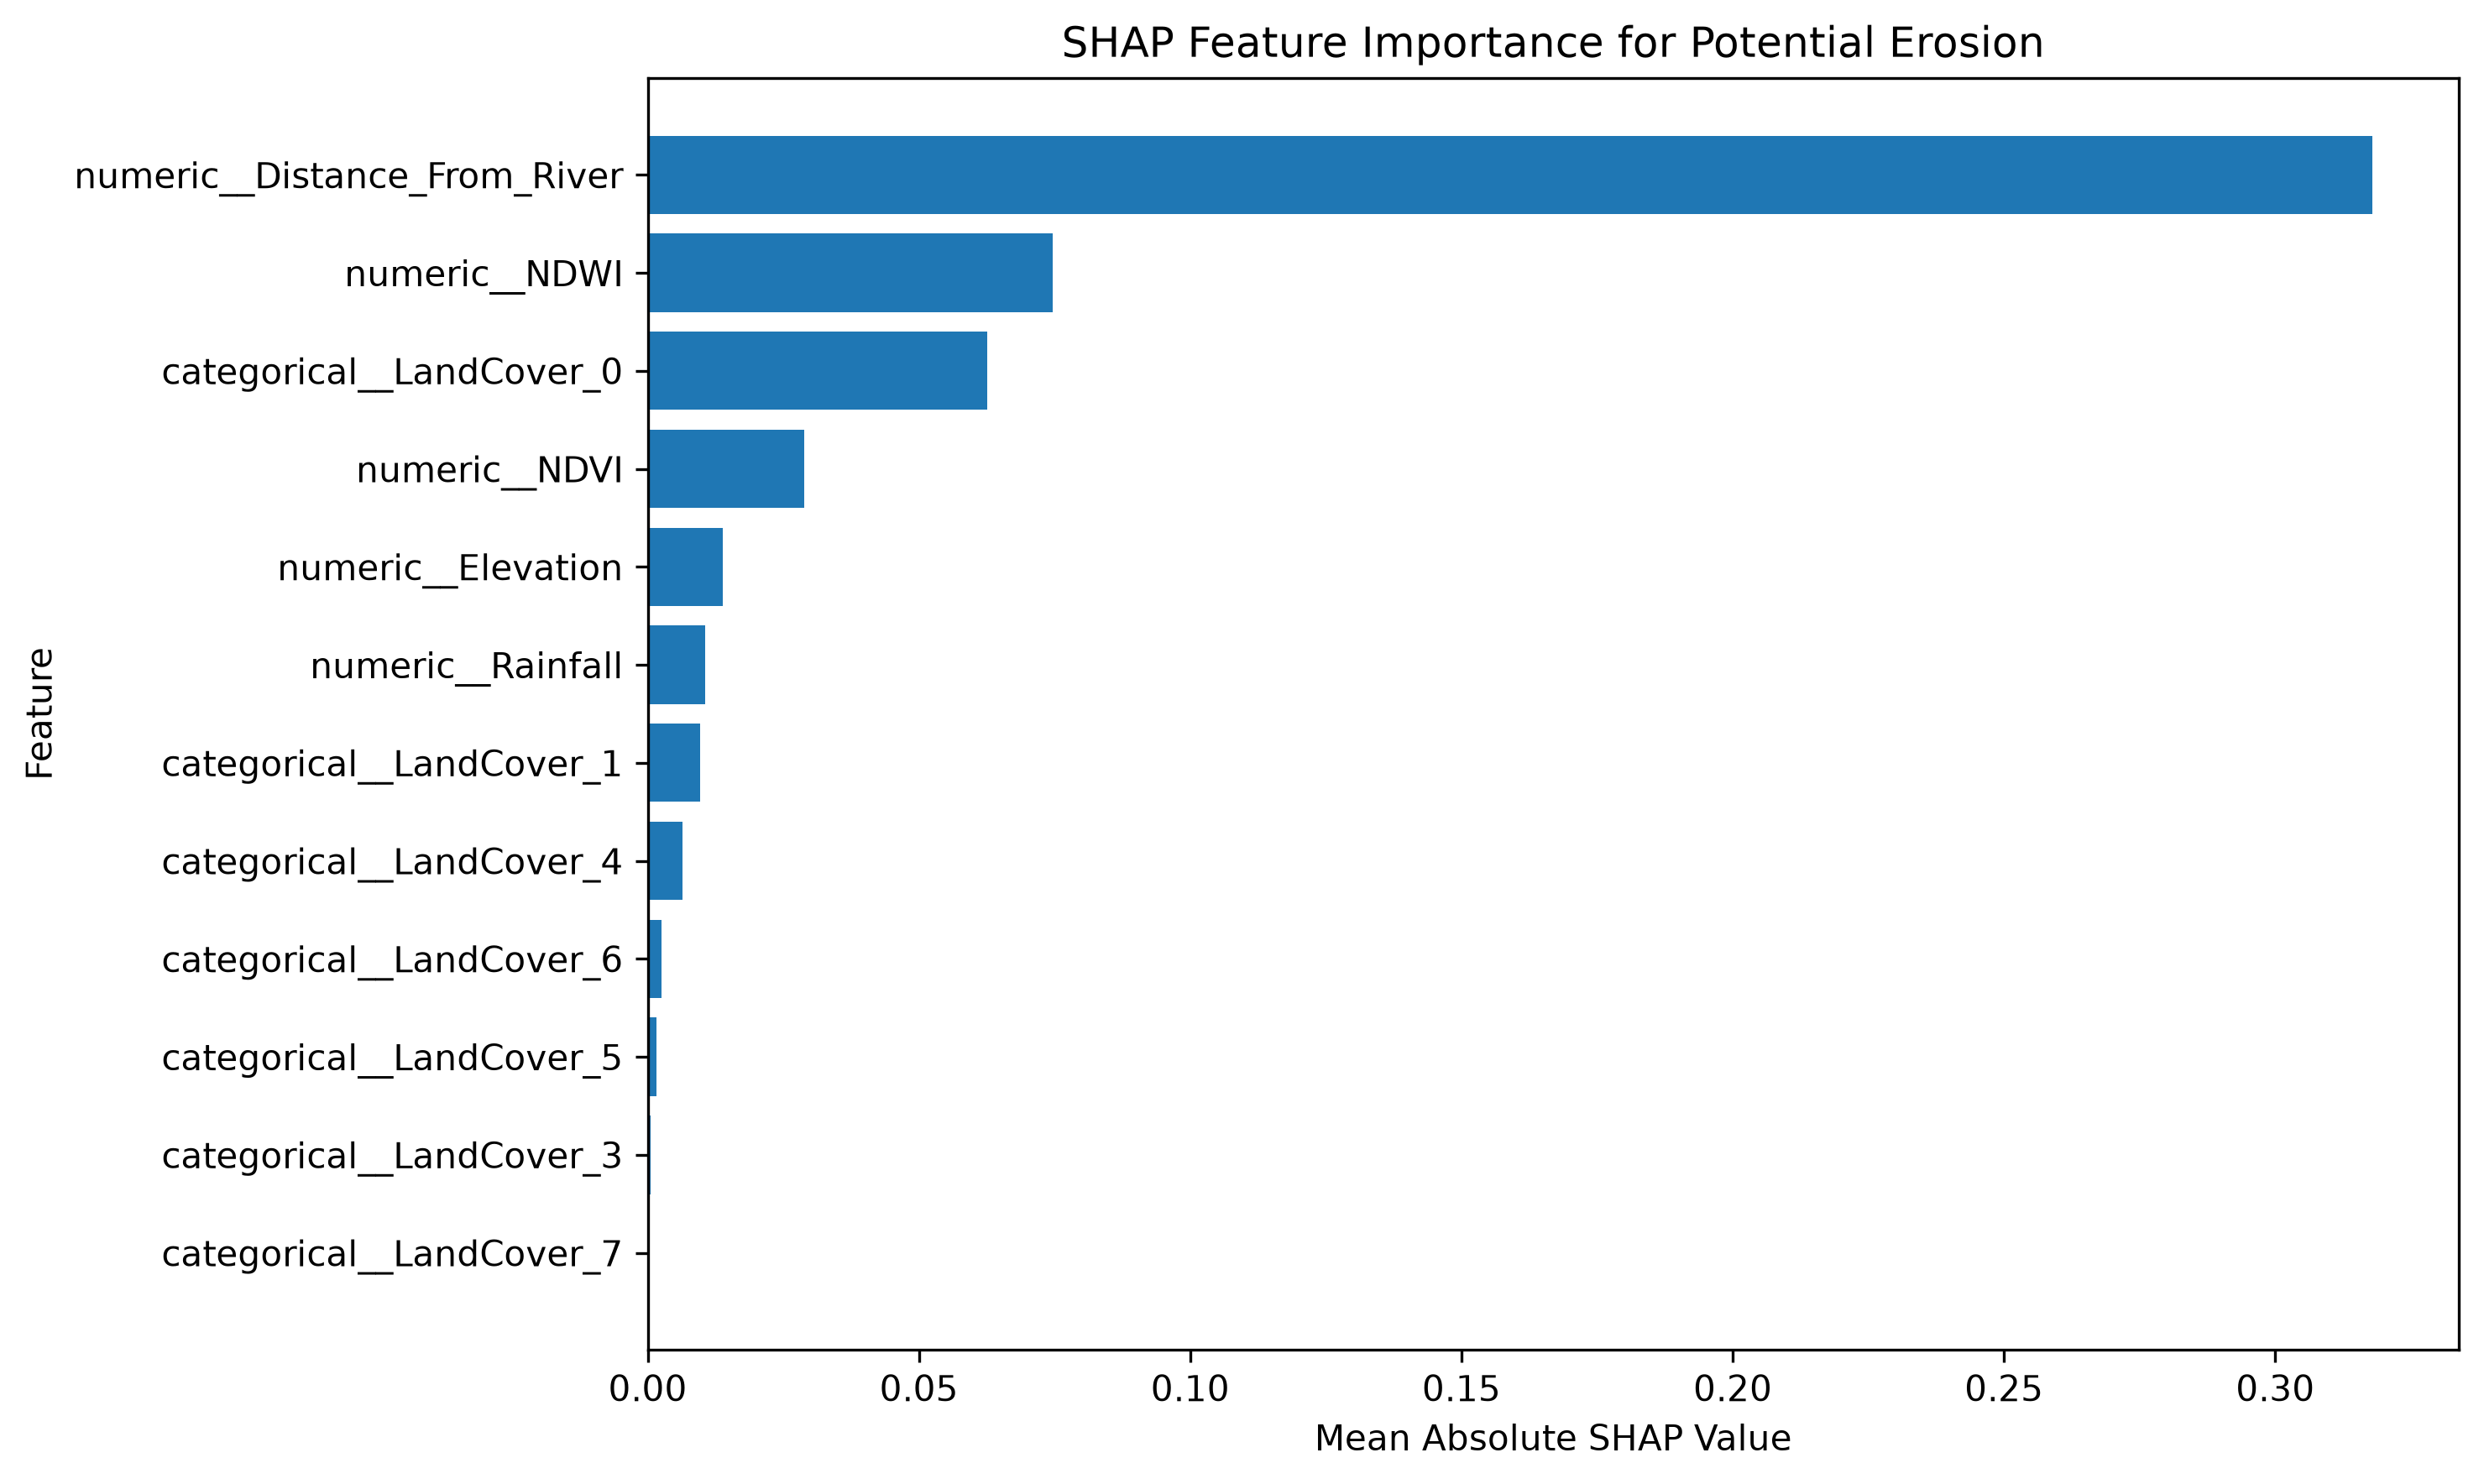

In [9]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

PROJECT_DIR = Path.cwd().parent
RESULTS_DIR = PROJECT_DIR / "results"

# Load the existing SHAP feature-importance CSV
shap_csv = RESULTS_DIR / "random_forest_shap_feature_importance.csv"

shap_importance = pd.read_csv(shap_csv)

print("SHAP importance file:", shap_csv)
print("\nColumns:", shap_importance.columns.tolist())
print("\nFeature importance values:")
display(shap_importance)

# Display the existing feature-importance chart
shap_plot = RESULTS_DIR / "random_forest_shap_feature_importance.png"

if shap_plot.exists():
    display(Image(filename=str(shap_plot)))


### SHAP-Based Interpretation of the Random Forest Model

SHAP feature-importance analysis was used to interpret the predictions of the trained Random Forest model. Mean absolute SHAP values identified Distance_From_River (0.317947) as the most influential feature, followed by NDWI (0.074651), the LandCover 0 indicator (0.062558), NDVI (0.028790), Elevation (0.013919), and Rainfall (0.010585).

The dominance of Distance_From_River is consistent with the exploratory analysis, which showed that potential-erosion samples were located much closer to the mapped river boundary than stable-proxy samples. NDWI and LandCover 0 were also influential, indicating that water-related spectral information and land-cover classification contribute substantially to the model's predictions. NDVI provided additional information about vegetation conditions, while elevation and rainfall had comparatively smaller global SHAP importance.

These results describe the features most influential to the fitted model, rather than establishing causal relationships. Since the target represents potential erosion derived from satellite-observed water contraction, the importance of river proximity and water-related predictors may partly reflect the construction of the target labels. Therefore, the model explanations are interpreted as associations with the satellite-derived potential-erosion proxy rather than confirmation of field-verified erosion mechanisms.

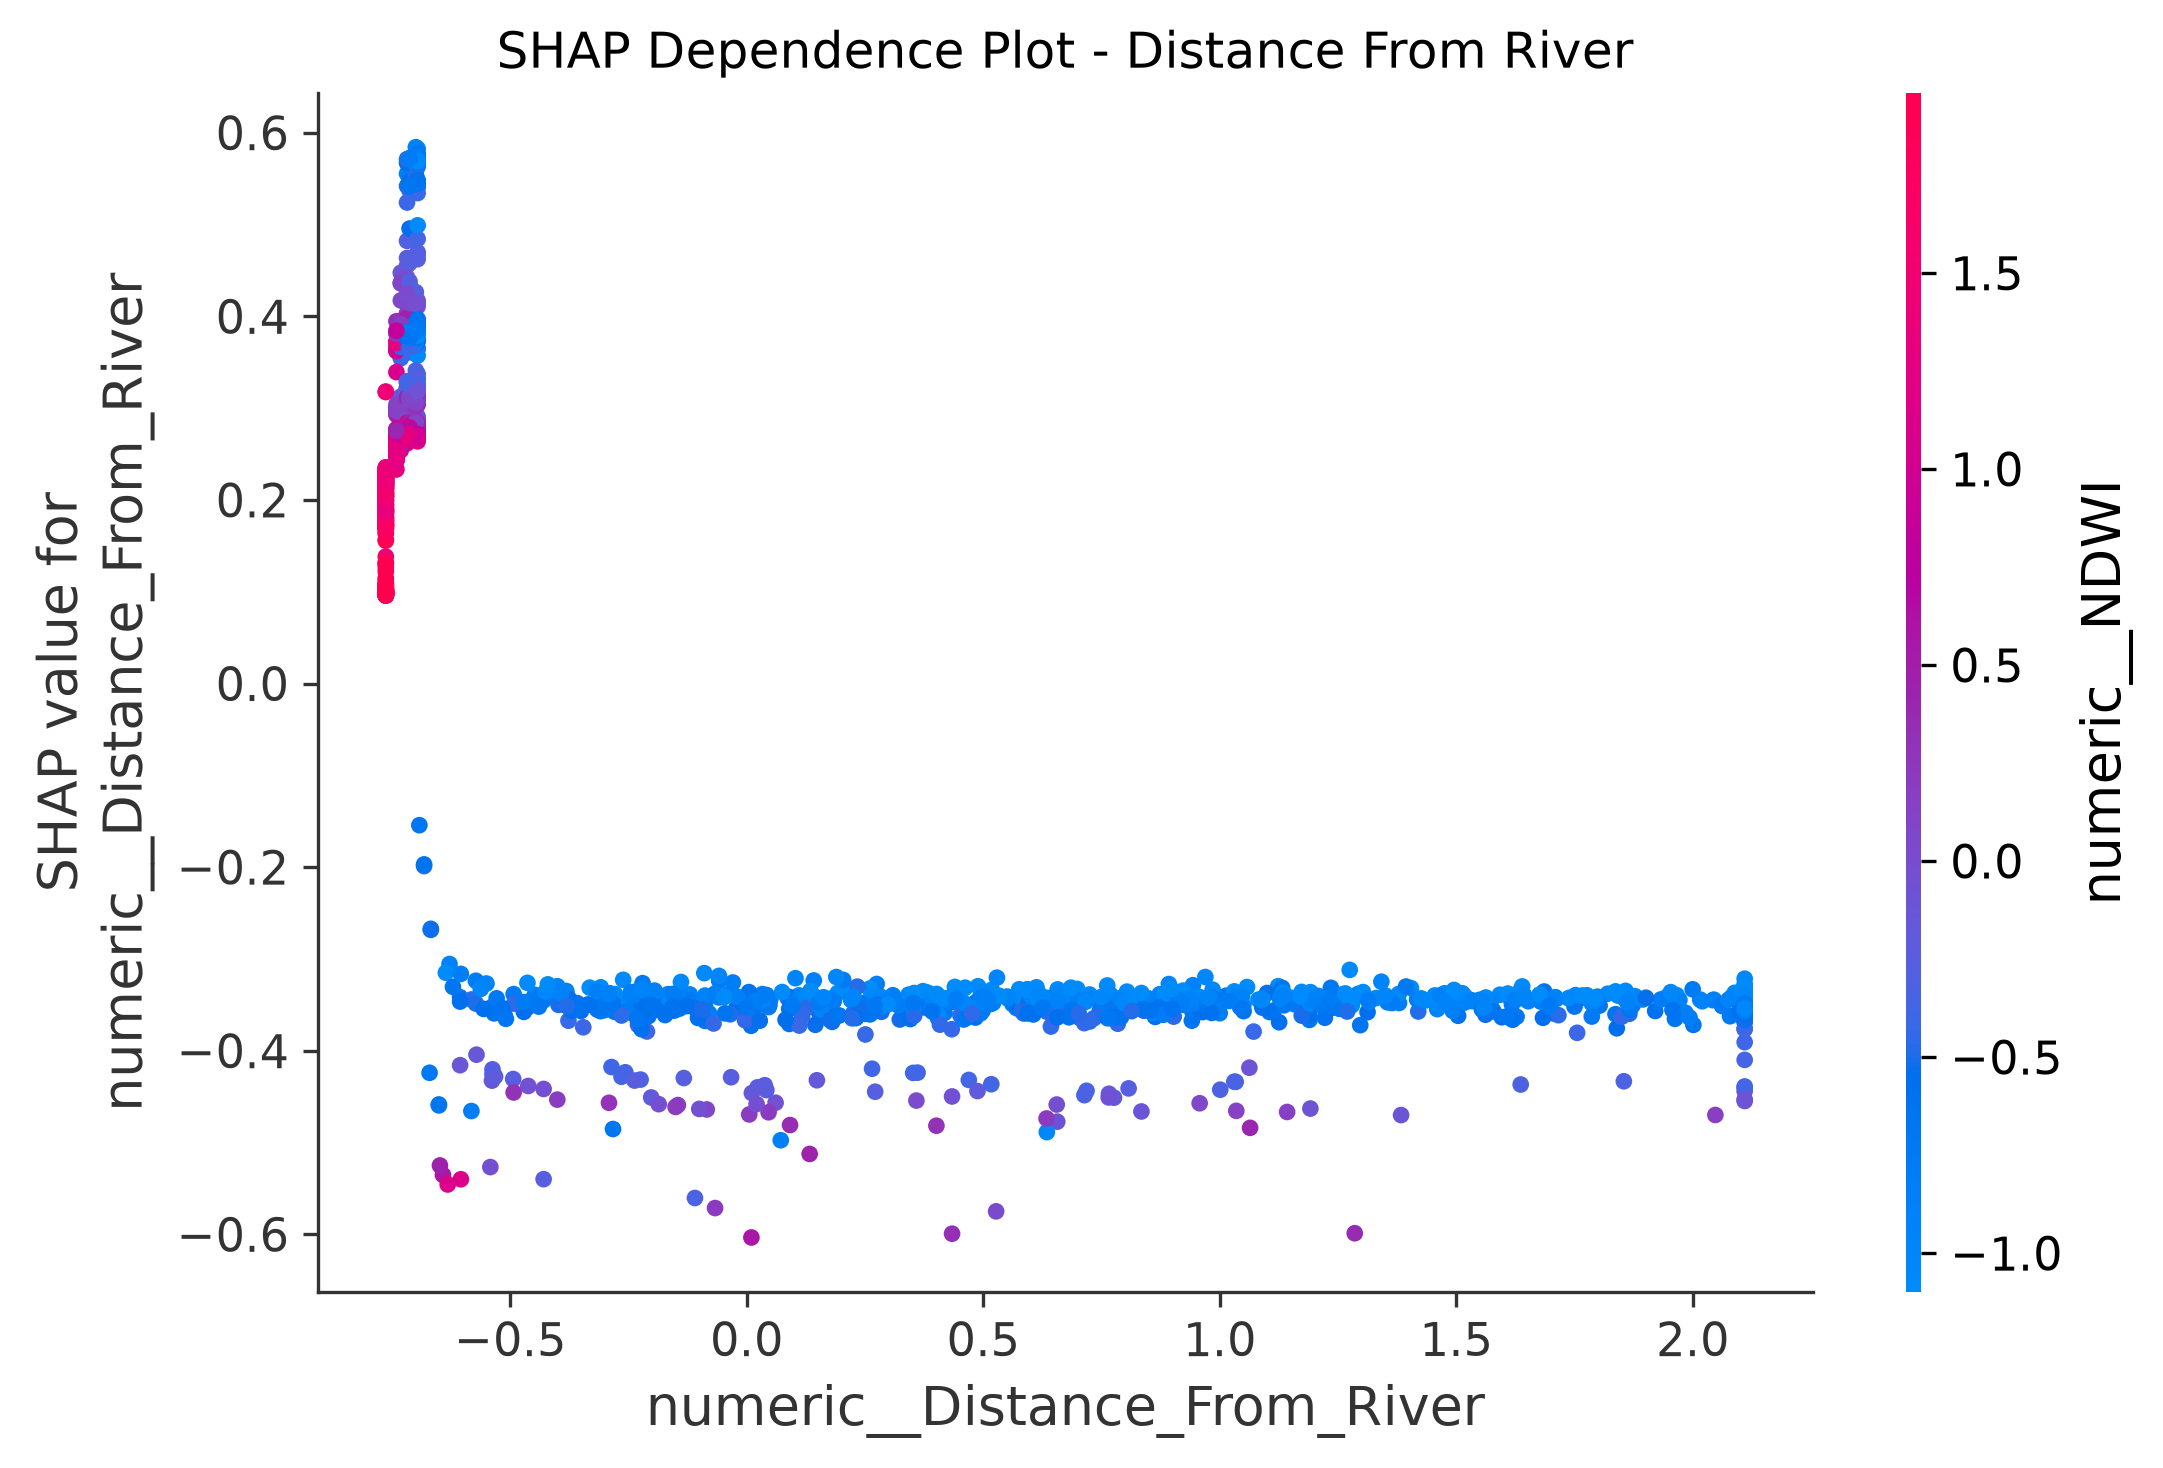

In [10]:

from IPython.display import Image, display

display(Image(
    filename=str(
        RESULTS_DIR / "shap_dependence_distance_from_river.png"
    )
))


SHAP Dependence: NDWI


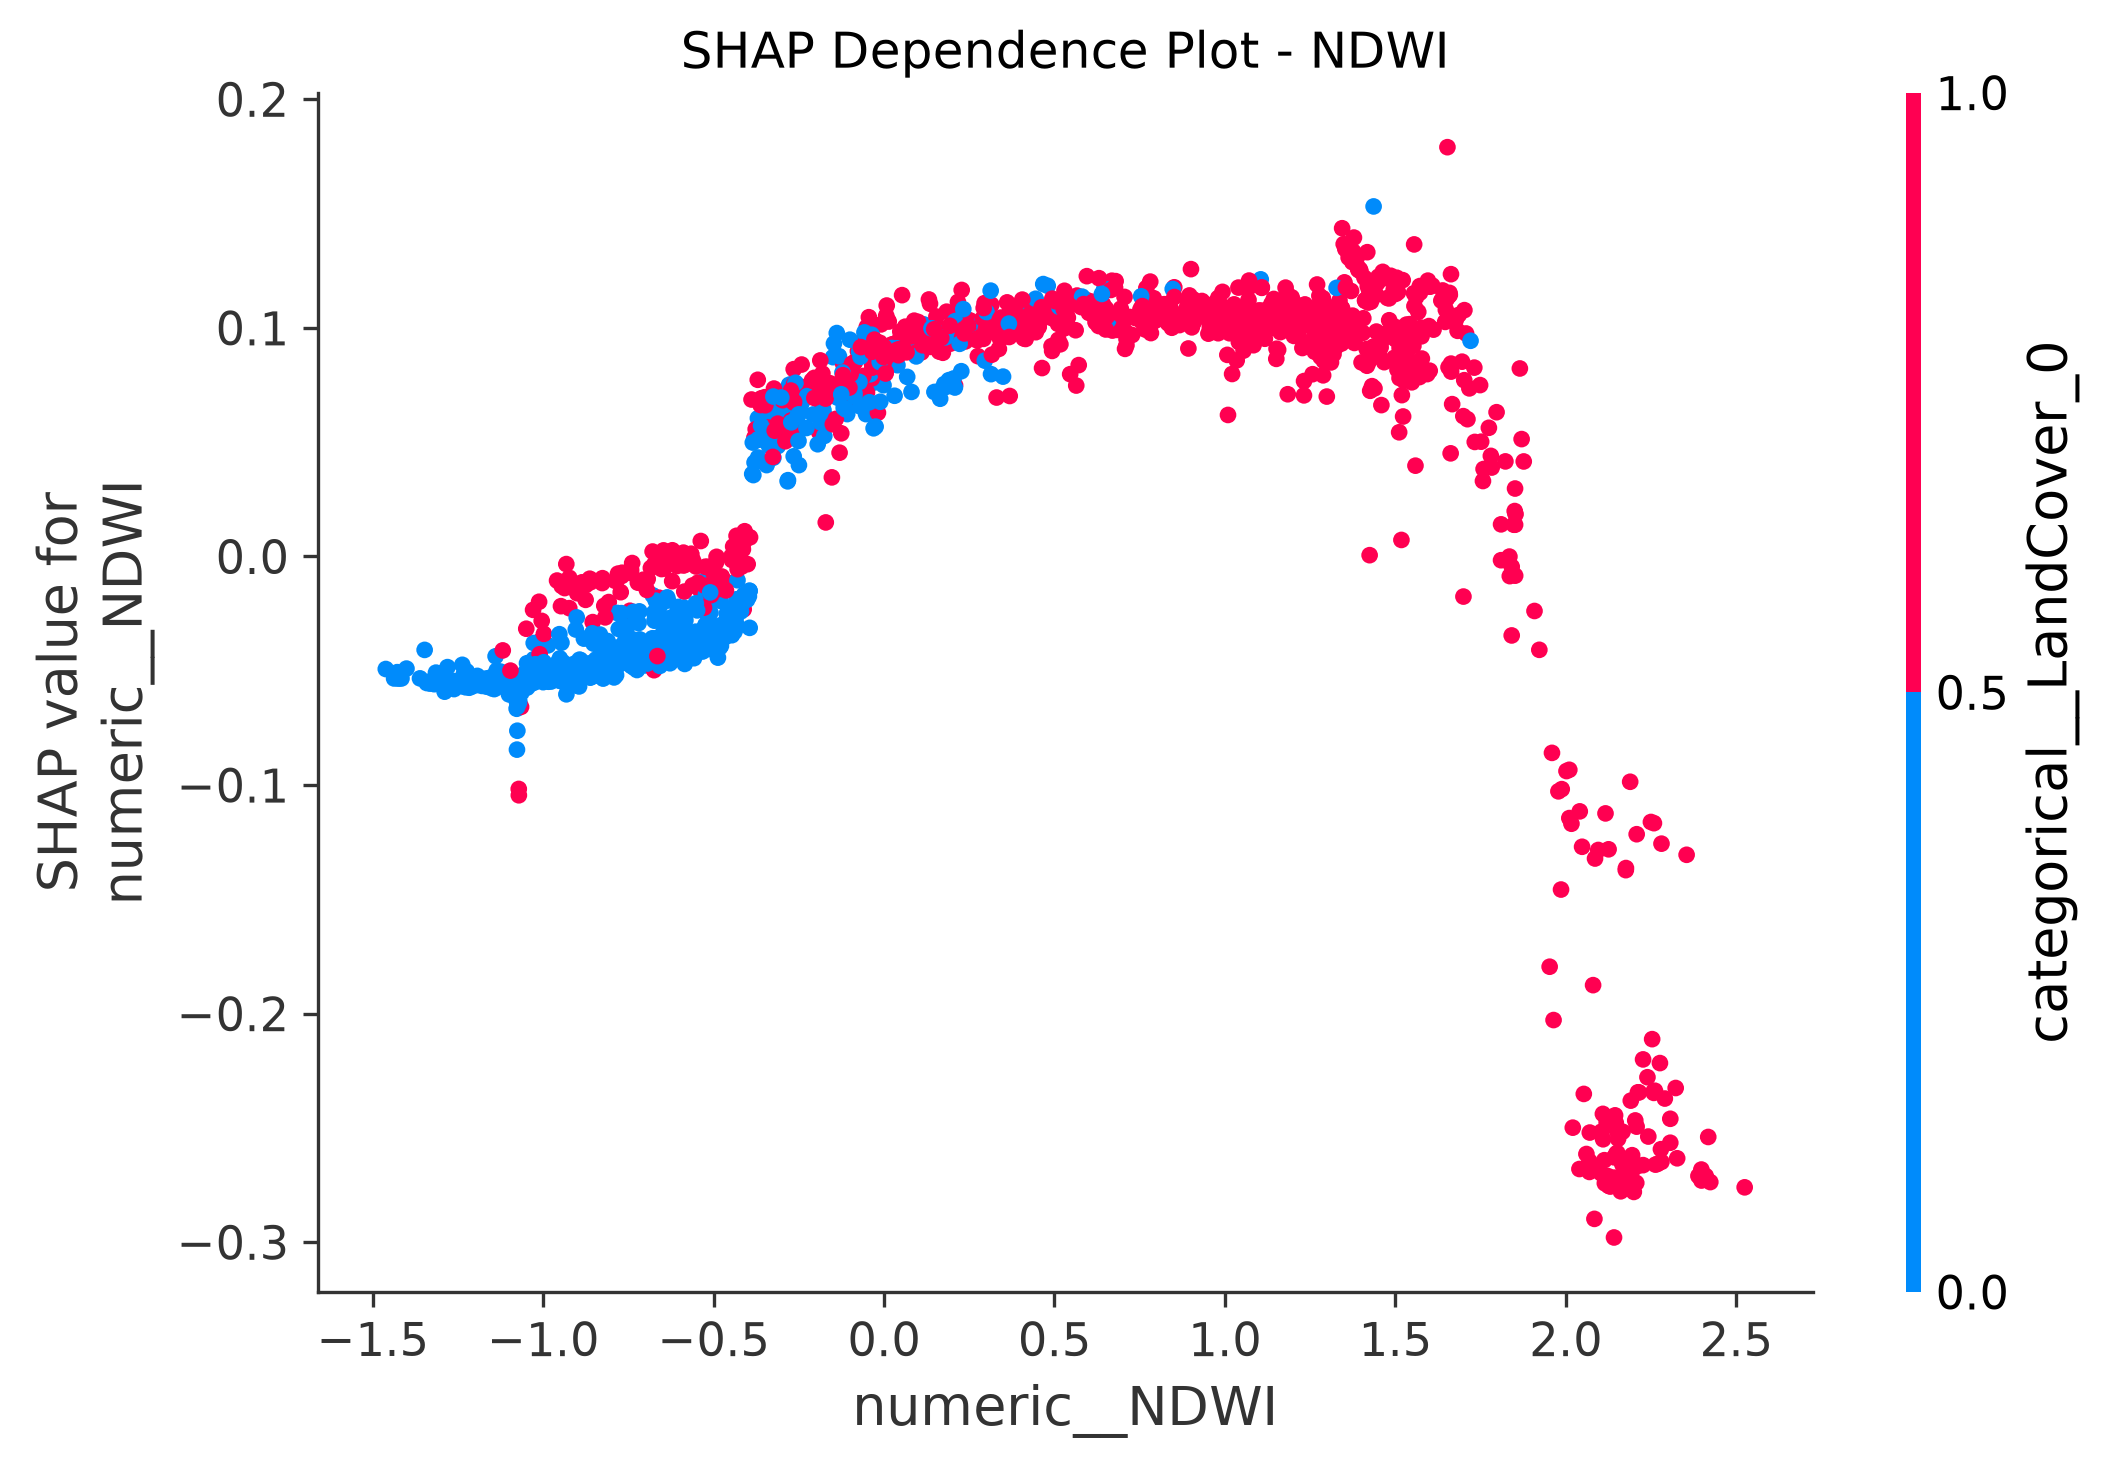

SHAP Dependence: NDVI


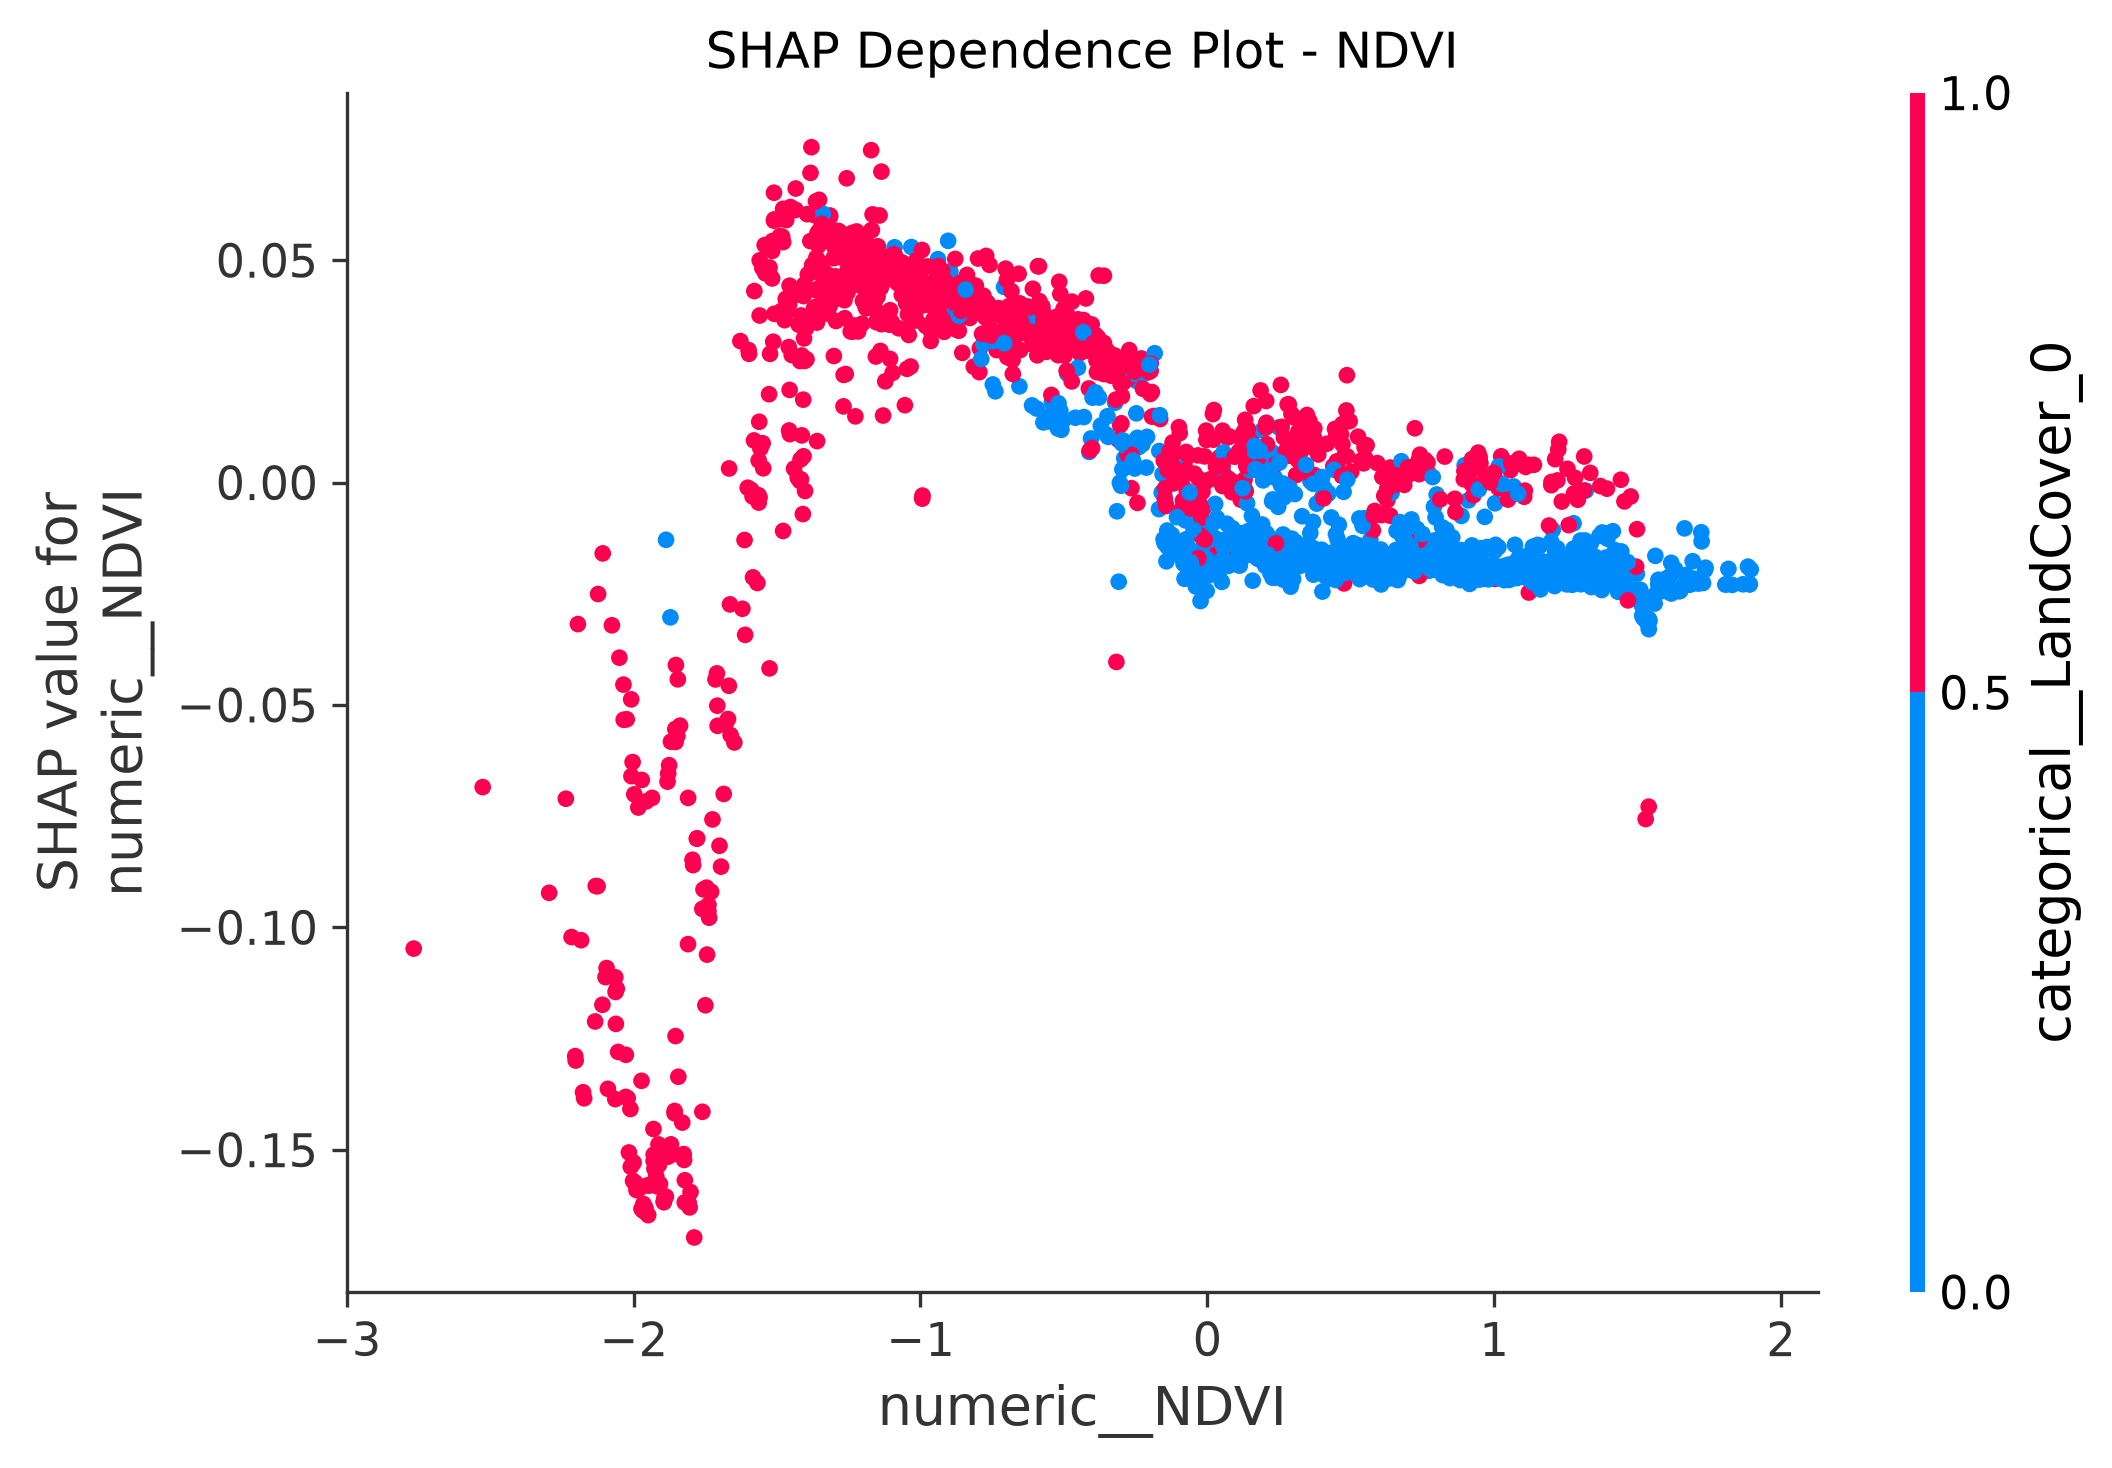

In [11]:

from IPython.display import Image, display

print("SHAP Dependence: NDWI")
display(Image(
    filename=str(RESULTS_DIR / "shap_dependence_ndwi.png")
))

print("SHAP Dependence: NDVI")
display(Image(
    filename=str(RESULTS_DIR / "shap_dependence_ndvi.png")
))


## Conclusion

This notebook examined the environmental characteristics associated with potential riverbank erosion along the Mahanadi River using the existing machine-learning dataset and SHAP explanations.

The exploratory analysis showed that potential-erosion samples had lower median NDVI, higher median NDWI, slightly lower median elevation, and a much smaller median distance from the mapped river boundary than stable-proxy samples. Land-cover composition also differed substantially between the two classes, particularly for category 0.

The SHAP feature-importance analysis identified Distance_From_River as the most influential feature, followed by NDWI, the LandCover 0 indicator, and NDVI. Elevation and rainfall had comparatively smaller mean absolute SHAP values. These results help explain which environmental variables the existing Random Forest model uses when making predictions.

However, the target labels represent potential erosion inferred from satellite-observed water contraction rather than field-verified erosion events. The strong influence of river distance and water-related variables may therefore partly reflect the label-generation method. The results should be interpreted as environmental associations with the satellite-derived proxy, not as proof of causal relationships or confirmed erosion.

Future work could incorporate field observations, independently verified erosion locations, additional temporal information, and validation in a separate geographic area to assess how well the model generalizes to real-world riverbank erosion.